## Cell 1 - Import dan konfigurasi
Atur `AUDIO_ROOT` ke folder yang berisi file .flac (subfolder ikut dicari).

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display

warnings.filterwarnings("ignore")

METADATA_CSV = "metadata.csv"
AUDIO_ROOT = r"data\schematics-2026\train\audio"
SR = 22050
MAX_SEC = 10
N_SAMPLE = 450
HP_CUTOFF = 400
SEED = 42

## Cell 2 - Baca metadata dan info dasar

In [2]:
df = pd.read_csv(METADATA_CSV)
idx = {}
for dp, dirs, fs in os.walk(AUDIO_ROOT):
    dirs[:] = [d for d in dirs if not d.startswith(".")]
    for f in fs:
        if f.lower().endswith(".flac"):
            idx[os.path.splitext(f)[0]] = os.path.join(dp, f)
print("working dir:", os.getcwd())
print("file flac ditemukan di", os.path.abspath(AUDIO_ROOT), ":", len(idx))
df["path"] = df["file_id"].map(idx)
df["exists"] = df["path"].notna()
df["grp"] = df["source_group"].str[:6]

print("shape:", df.shape)
print(df.dtypes)
print("\nmissing value:")
print(df.isna().sum())
print("\nduplikat file_id:", df["file_id"].duplicated().sum())
print("jumlah label:", df["label"].nunique(), "| jumlah source_group:", df["source_group"].nunique())
print("file audio ditemukan:", df["exists"].sum(), "dari", len(df))
df.head()

working dir: c:\Coding\Kaggle Comp\NPC DatSci 2026
file flac ditemukan di c:\Coding\Kaggle Comp\NPC DatSci 2026\data\schematics-2026\train\audio : 1826
shape: (1826, 7)
file_id          str
audio_path       str
label            str
source_group     str
path             str
exists          bool
grp              str
dtype: object

missing value:
file_id         0
audio_path      0
label           0
source_group    0
path            0
exists          0
grp             0
dtype: int64

duplikat file_id: 0
jumlah label: 3 | jumlah source_group: 15
file audio ditemukan: 1826 dari 1826


,file_id,audio_path,label,source_group,path,exists,grp
0,313fef340a5c0be86a6c3ec29bb0fc5b684accd321f994...,train/audio/313fef340a5c0be86a6c3ec29bb0fc5b68...,Bondol Jawa,d20bbb9d3f16cea2e0988846afe752fa7233d9de8cffd7...,data\schematics-2026\train\audio\313fef340a5c0...,True,d20bbb
1,9f0d58ab5eb8bdad788915ba9053c9a23b2709461ee290...,train/audio/9f0d58ab5eb8bdad788915ba9053c9a23b...,Bondol Jawa,100f6ca56523c6b10f0da48fca4a3100f7e2fad1a2c238...,data\schematics-2026\train\audio\9f0d58ab5eb8b...,True,100f6c
2,f18d5438129a6c8fabe09f8d108c44b0fa40880cf0ffcb...,train/audio/f18d5438129a6c8fabe09f8d108c44b0fa...,Kutilang,81b28e5fe98ace507d968e64f7cf87d7c4af112b8d3d19...,data\schematics-2026\train\audio\f18d5438129a6...,True,81b28e
3,ec4ea61e4451227b2ee1e4046296b515e4f58761ea4097...,train/audio/ec4ea61e4451227b2ee1e4046296b515e4...,Bondol Jawa,d20bbb9d3f16cea2e0988846afe752fa7233d9de8cffd7...,data\schematics-2026\train\audio\ec4ea61e44512...,True,d20bbb
4,d0bd6e1839642188508060a7bb5c29c1a8251ada1a48f0...,train/audio/d0bd6e1839642188508060a7bb5c29c1a8...,Kutilang,0d9c30be6d4b5d92c8384b9e5fd3cf908e4b8a965c68a9...,data\schematics-2026\train\audio\d0bd6e1839642...,True,0d9c30


## Cell 3 - Distribusi label

             jumlah  persen
label                      
Bondol Jawa    1124    61.6
Kutilang        619    33.9
Cendrawasih      83     4.5
rasio imbalance (terbesar / terkecil): 13.5


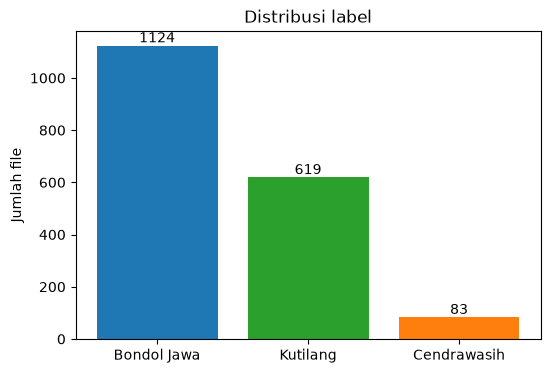

In [3]:
vc = df["label"].value_counts()
colors = {l: f"C{i}" for i, l in enumerate(sorted(df["label"].unique()))}

print(pd.DataFrame({"jumlah": vc, "persen": (vc / len(df) * 100).round(1)}))
print("rasio imbalance (terbesar / terkecil):", round(vc.max() / vc.min(), 1))

plt.figure(figsize=(6, 4))
plt.bar(vc.index, vc.values, color=[colors[l] for l in vc.index])
for i, v in enumerate(vc.values):
    plt.text(i, v, str(v), ha="center", va="bottom")
plt.title("Distribusi label")
plt.ylabel("Jumlah file")
plt.show()

## Cell 4 - Distribusi source_group dan hubungannya dengan label

        jumlah  n_label        label
grp                                 
d20bbb     336        1  Bondol Jawa
6b8570     232        1  Bondol Jawa
c04cd5     176        1  Bondol Jawa
90eace     123        1  Bondol Jawa
100f6c     117        1  Bondol Jawa
347254      82        1  Bondol Jawa
feb851      58        1  Bondol Jawa
8a3900      35        1  Cendrawasih
6895fb      29        1  Cendrawasih
660c17      16        1  Cendrawasih
d7bc3d       3        1  Cendrawasih
e6af04     178        1     Kutilang
81213a     166        1     Kutilang
81b28e     143        1     Kutilang
0d9c30     132        1     Kutilang

group dengan lebih dari 1 label: 0

jumlah group per label:
label
Bondol Jawa    7
Cendrawasih    4
Kutilang       4
Name: source_group, dtype: int64


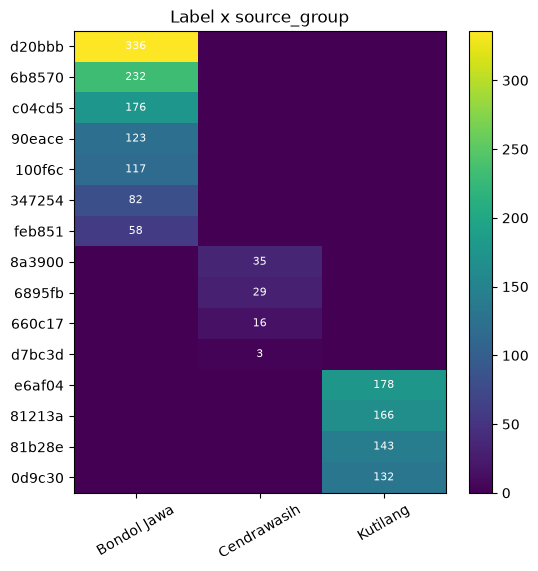

In [4]:
g = (df.groupby("grp")
       .agg(jumlah=("file_id", "size"), n_label=("label", "nunique"), label=("label", "first"))
       .sort_values(["label", "jumlah"], ascending=[True, False]))
order = g.index.tolist()

print(g)
print("\ngroup dengan lebih dari 1 label:", (g["n_label"] > 1).sum())
print("\njumlah group per label:")
print(df.groupby("label")["source_group"].nunique())

ct = pd.crosstab(df["grp"], df["label"]).loc[order]
plt.figure(figsize=(6, 6))
plt.imshow(ct.values, aspect="auto", cmap="viridis")
plt.xticks(range(ct.shape[1]), ct.columns, rotation=30)
plt.yticks(range(ct.shape[0]), ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        if ct.values[i, j] > 0:
            plt.text(j, i, ct.values[i, j], ha="center", va="center", color="white", fontsize=8)
plt.colorbar()
plt.title("Label x source_group")
plt.show()

## Cell 5 - Komposisi label tiap fold (StratifiedGroupKFold)

In [5]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for i, (tr, va) in enumerate(sgkf.split(df, df["label"], df["source_group"])):
    r = df.iloc[va]["label"].value_counts().to_dict()
    r.update(fold=i, n_val=len(va), n_group=df.iloc[va]["source_group"].nunique())
    rows.append(r)
print(pd.DataFrame(rows).fillna(0).astype(int).set_index("fold"))

      Bondol Jawa  Cendrawasih  n_val  n_group  Kutilang
fold                                                    
0             336           29    365        2         0
1             232            3    367        3       132
2             199            0    377        3       178
3             176           35    354        3       143
4             181           16    363        4       166


## Cell 6 - Durasi audio (hanya membaca header file)

In [6]:
assert df["exists"].any(), "Tidak ada file audio ditemukan. Periksa AUDIO_ROOT."

def get_dur(p):
    try:
        return librosa.get_duration(path=p)
    except Exception:
        return np.nan

df["duration"] = [get_dur(p) if e else np.nan for p, e in zip(df["path"], df["exists"])]

print("gagal dibaca:", df.loc[df["exists"], "duration"].isna().sum())
print(df["duration"].describe(percentiles=[.05, .5, .95, .99]).round(2))
print("\ndurasi per label:")
print(df.groupby("label")["duration"].describe().round(2))
print("\ntotal durasi (jam):", round(df["duration"].sum() / 3600, 2))
print("estimasi RAM waveform (GB):", round(df["duration"].sum() * SR * 4 / 1e9, 2))

gagal dibaca: 0
count    1826.00
mean       10.04
std         2.17
min         5.27
5%          6.40
50%        10.03
95%        13.63
99%        14.42
max        14.90
Name: duration, dtype: float64

durasi per label:
              count   mean   std   min   25%    50%    75%    max
label                                                            
Bondol Jawa  1124.0   9.91  2.18  5.27  8.28   9.89  11.58  14.90
Cendrawasih    83.0  10.43  2.23  5.68  8.79  10.27  11.90  14.65
Kutilang      619.0  10.22  2.14  5.56  8.57  10.34  11.81  14.90

total durasi (jam): 5.09
estimasi RAM waveform (GB): 1.62


## Cell 7 - Grafik durasi

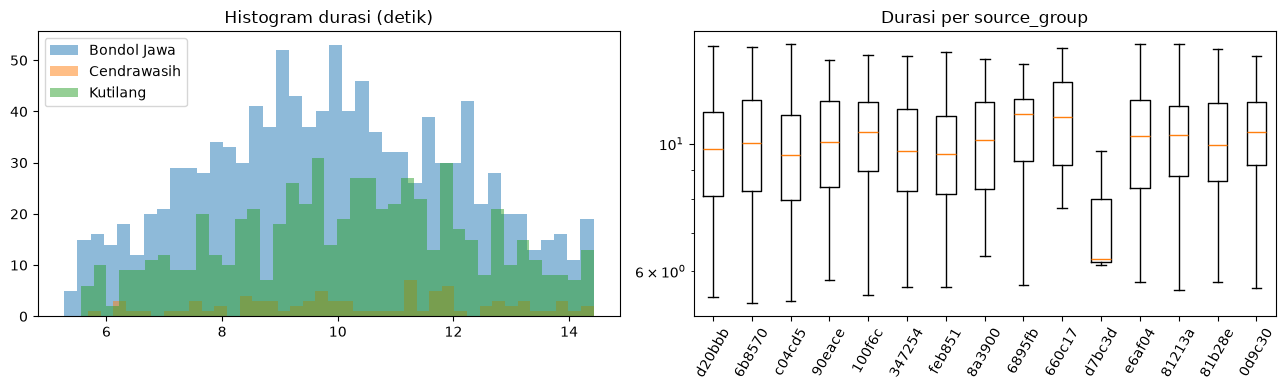

In [7]:
d = df.dropna(subset=["duration"])
hi = d["duration"].quantile(0.99)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for l, c in colors.items():
    ax[0].hist(d.loc[d["label"] == l, "duration"].clip(upper=hi), bins=40, alpha=0.5, color=c, label=l)
ax[0].legend()
ax[0].set_title("Histogram durasi (detik)")

ax[1].boxplot([d.loc[d["grp"] == o, "duration"] for o in order])
ax[1].set_xticks(range(1, len(order) + 1))
ax[1].set_xticklabels(order, rotation=60)
ax[1].set_yscale("log")
ax[1].set_title("Durasi per source_group")
plt.tight_layout()
plt.show()

## Cell 8 - Ekstraksi fitur audio pada sampel
Sampel diambil merata per source_group. 

In [8]:
d = df[df["exists"] & df["duration"].notna()].copy()
d["r"] = np.random.RandomState(SEED).rand(len(d))
per = max(5, N_SAMPLE // d["source_group"].nunique())
sub = d.sort_values("r").groupby("source_group").head(per).reset_index(drop=True)
print(len(sub), "file sampel")

freqs = librosa.fft_frequencies(sr=SR, n_fft=1024)
rows, psds = [], []
for i, p in enumerate(sub["path"]):
    y, _ = librosa.load(p, sr=SR, mono=True, duration=MAX_SEC)
    if len(y) < 2048:
        y = np.pad(y, (0, 2048 - len(y)), mode="wrap")
    S = np.abs(librosa.stft(y, n_fft=1024, hop_length=256)) ** 2
    mag = np.sqrt(S)
    tot = S.sum() + 1e-12
    e_db = 10 * np.log10(S.sum(0) + 1e-10)
    rows.append(dict(
        rms=librosa.feature.rms(y=y).mean(),
        peak=np.abs(y).max(),
        clip_ratio=(np.abs(y) >= 0.99).mean(),
        silence_ratio=(e_db < e_db.max() - 40).mean(),
        low_freq_ratio=S[freqs < 500].sum() / tot,
        high_freq_ratio=S[freqs >= 4000].sum() / tot,
        centroid=librosa.feature.spectral_centroid(S=mag, sr=SR).mean(),
        bandwidth=librosa.feature.spectral_bandwidth(S=mag, sr=SR).mean(),
        rolloff=librosa.feature.spectral_rolloff(S=mag, sr=SR).mean(),
        flatness=librosa.feature.spectral_flatness(S=mag).mean(),
        zcr=librosa.feature.zero_crossing_rate(y).mean(),
    ))
    psds.append(S.mean(1))
    if (i + 1) % 100 == 0:
        print(i + 1, "/", len(sub))

FEATS = list(rows[0].keys())
feat = pd.concat([sub, pd.DataFrame(rows)], axis=1)
psd_db = 10 * np.log10(np.array(psds) + 1e-12)

print("\nrata-rata fitur per label:")
print(feat.groupby("label")[FEATS].mean().round(4).T)
print("\nfile dengan clipping:", (feat["clip_ratio"] > 0.001).sum())
print("file dengan silence_ratio > 0.5:", (feat["silence_ratio"] > 0.5).sum())

408 file sampel
100 / 408
200 / 408
300 / 408
400 / 408

rata-rata fitur per label:
label            Bondol Jawa  Cendrawasih   Kutilang
rms                   0.0790       0.0813     0.0835
peak                  0.7212       0.6653     0.6680
clip_ratio            0.0000       0.0000     0.0000
silence_ratio         0.0000       0.0000     0.0000
low_freq_ratio        0.1387       0.1527     0.1394
high_freq_ratio       0.3805       0.3517     0.2034
centroid           4043.3370    4219.3490  3974.8708
bandwidth          2619.6908    2655.2180  2669.0799
rolloff            6960.8560    7173.6770  7039.0773
flatness              0.0944       0.0921     0.1013
zcr                   0.3183       0.3467     0.2995

file dengan clipping: 0
file dengan silence_ratio > 0.5: 0


## Cell 9 - Perbandingan fitur antar label

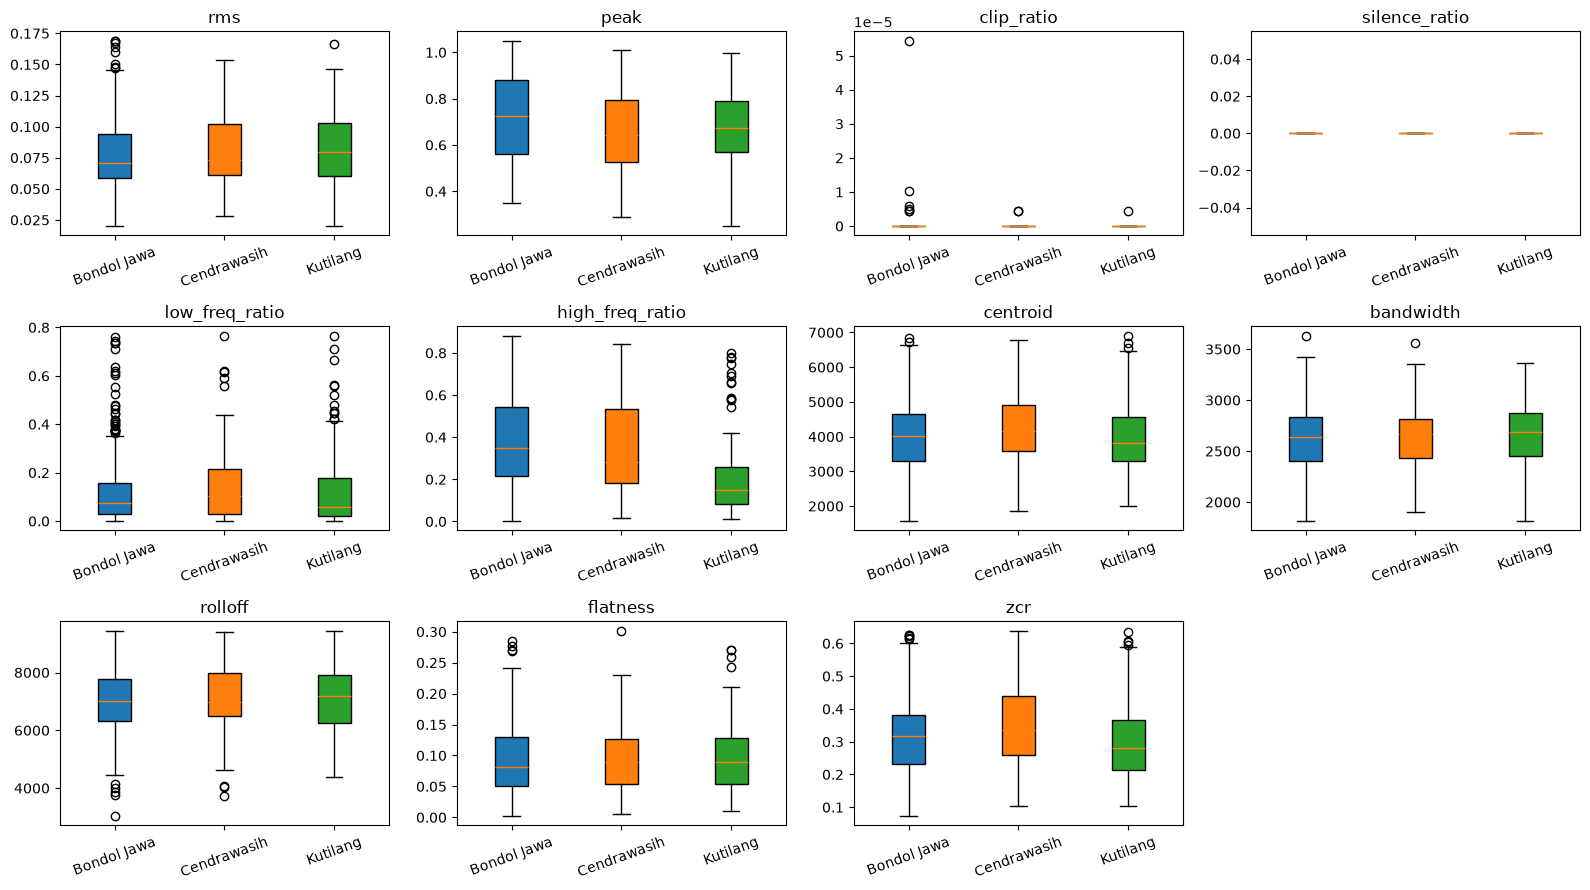

In [9]:
labs = list(colors)
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, f in zip(axes.ravel(), FEATS):
    bp = ax.boxplot([feat.loc[feat["label"] == l, f] for l in labs], patch_artist=True)
    for b, l in zip(bp["boxes"], labs):
        b.set_facecolor(colors[l])
    ax.set_xticks(range(1, len(labs) + 1))
    ax.set_xticklabels(labs, rotation=20)
    ax.set_title(f)
for ax in axes.ravel()[len(FEATS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Cell 10 - Karakter rekaman per source_group

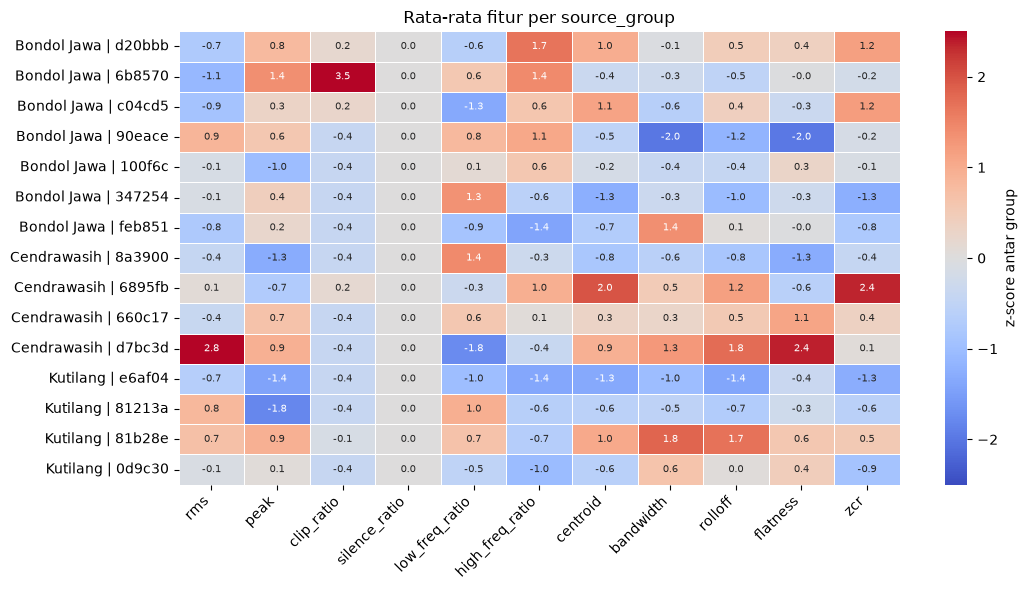

In [10]:
import seaborn as sns

z = feat.groupby("grp")[FEATS].mean().loc[order]
z = (z - z.mean()) / (z.std() + 1e-12)
z.index = [f"{g.loc[o, 'label']} | {o}" for o in order]

plt.figure(figsize=(11, 6))
sns.heatmap(
    z,
    cmap="coolwarm",
    vmin=-2.5,
    vmax=2.5,
    annot=True,
    fmt=".1f",
    annot_kws={"size": 7},
    linewidths=0.5,
    cbar_kws={"label": "z-score antar group"},
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.title("Rata-rata fitur per source_group")
plt.tight_layout()
plt.show()

## Cell 11 - Spektrum daya (cek cutoff high-pass)

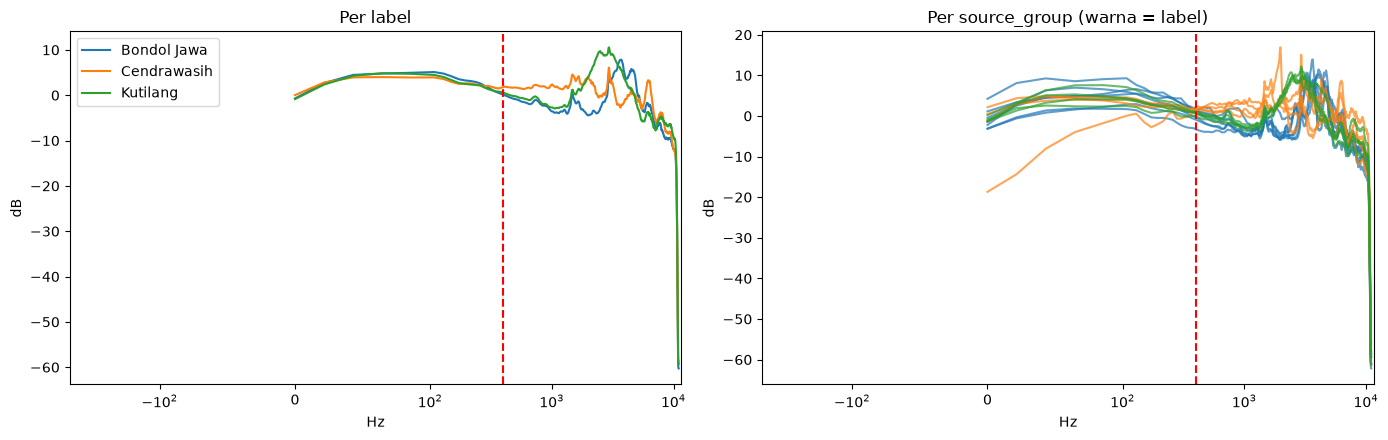

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for l, c in colors.items():
    ax[0].plot(freqs, psd_db[(feat["label"] == l).values].mean(0), color=c, label=l)
for o in order:
    m = (feat["grp"] == o).values
    ax[1].plot(freqs, psd_db[m].mean(0), color=colors[g.loc[o, "label"]], alpha=0.7)
ax[0].legend()
ax[0].set_title("Per label")
ax[1].set_title("Per source_group (warna = label)")
for a in ax:
    a.axvline(HP_CUTOFF, color="red", ls="--")
    a.set_xscale("symlog", linthresh=100)
    a.set_xlabel("Hz")
    a.set_ylabel("dB")
plt.tight_layout()
plt.show()

## Cell 12 - Contoh waveform dan spektrogram tiap label

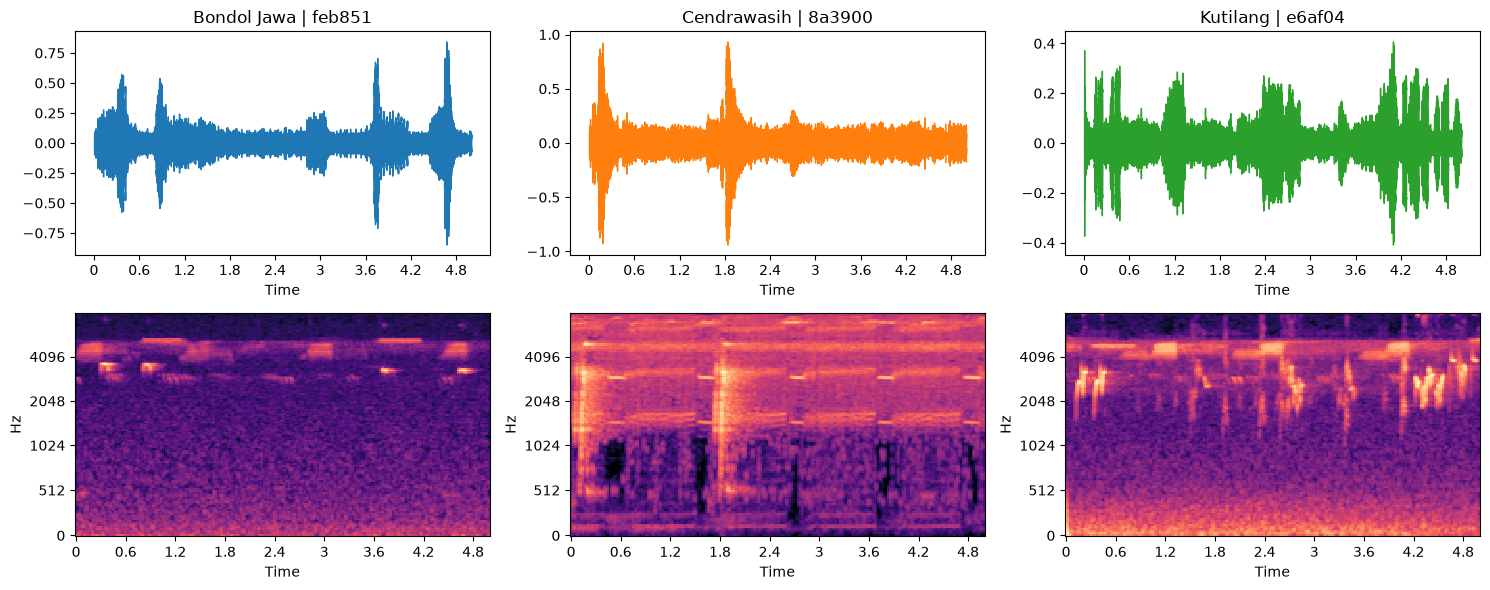

In [12]:
fig, axes = plt.subplots(2, len(colors), figsize=(5 * len(colors), 6))
for k, l in enumerate(colors):
    s = feat[feat["label"] == l]
    row = s.iloc[(s["duration"] - s["duration"].median()).abs().values.argmin()]
    y, _ = librosa.load(row["path"], sr=SR, mono=True, duration=5)
    librosa.display.waveshow(y, sr=SR, ax=axes[0, k], color=colors[l])
    axes[0, k].set_title(f"{l} | {row['grp']}")
    mel = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_mels=128, fmax=8000), ref=np.max)
    librosa.display.specshow(mel, sr=SR, x_axis="time", y_axis="mel", fmax=8000, ax=axes[1, k])
plt.tight_layout()
plt.show()

## Cell 13 - PCA (label vs source_group)

varians PC1, PC2: [0.387 0.188]


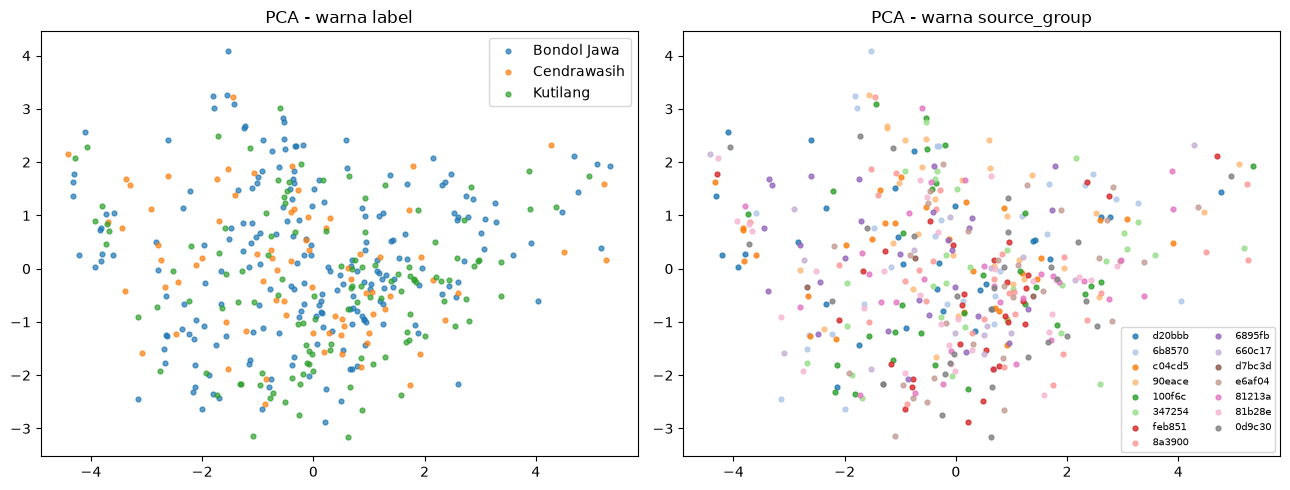

In [13]:
X = feat[FEATS].values
X = (X - X.mean(0)) / (X.std(0) + 1e-12)
_, sv, Vt = np.linalg.svd(X, full_matrices=False)
P = X @ Vt[:2].T
print("varians PC1, PC2:", ((sv ** 2) / np.sum(sv ** 2))[:2].round(3))

cm = plt.get_cmap("tab20")
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for l, c in colors.items():
    m = (feat["label"] == l).values
    ax[0].scatter(P[m, 0], P[m, 1], s=12, color=c, alpha=0.7, label=l)
for i, o in enumerate(order):
    m = (feat["grp"] == o).values
    ax[1].scatter(P[m, 0], P[m, 1], s=12, color=cm(i), alpha=0.8, label=o)
ax[0].set_title("PCA - warna label")
ax[1].set_title("PCA - warna source_group")
ax[0].legend()
ax[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

## Cell 14 - Uji kebocoran: CV acak vs CV berbasis group

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, accuracy_score

Xf = np.array(feat[FEATS].values)
y_lab = np.array(feat["label"].values)
y_grp = np.array(feat["source_group"].values)
clf = RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

p_rand = cross_val_predict(clf, Xf, y_lab, cv=skf)
p_group = cross_val_predict(clf, Xf, y_lab, cv=sgkf, groups=y_grp)
p_grp = cross_val_predict(clf, Xf, y_grp, cv=skf)
p_rand_prob = cross_val_predict(clf, Xf, y_lab, cv=skf, method="predict_proba")

print("prediksi label, CV acak     -> macro-F1:", round(f1_score(y_lab, p_rand, average="macro"), 4),
      "| akurasi:", round(accuracy_score(y_lab, p_rand), 4))
print("prediksi label, CV per group -> macro-F1:", round(f1_score(y_lab, p_group, average="macro"), 4),
      "| akurasi:", round(accuracy_score(y_lab, p_group), 4))
print("\nprediksi source_group dari fitur (CV acak) -> akurasi:", round(accuracy_score(y_grp, p_grp), 4),
      "| tebakan acak ~", round(1 / len(np.unique(y_grp)), 4))
print("\nprobabilitas prediksi (CV acak):")
p_rand_prob

prediksi label, CV acak     -> macro-F1: 0.5579 | akurasi: 0.6029
prediksi label, CV per group -> macro-F1: 0.4469 | akurasi: 0.4975

prediksi source_group dari fitur (CV acak) -> akurasi: 0.1936 | tebakan acak ~ 0.0667

probabilitas prediksi (CV acak):


array([[0.08333333, 0.17666667, 0.74      ],
       [0.85666667, 0.08      , 0.06333333],
       [0.23      , 0.19333333, 0.57666667],
       ...,
       [0.34333333, 0.53      , 0.12666667],
       [0.27666667, 0.47      , 0.25333333],
       [0.44666667, 0.44333333, 0.11      ]], shape=(408, 3))

In [16]:
sub = pd.read_csv("submission/submission_kfold.csv")
ref = pd.read_csv("submission_all_unknown.csv")

print(sub.shape, ref.shape)
print(list(sub.columns))
print("jumlah baris sama:", len(sub) == len(ref))
print("file_id sama dan urutan sama:", len(sub) == len(ref) and (sub["file_id"].values == ref["file_id"].values).all())
print("label valid:", sub["label"].isin(["Bondol Jawa", "Cendrawasih", "Kutilang", "Unknown"]).all())
print(sub["label"].value_counts(normalize=True).round(3))

(814, 2) (814, 2)
['file_id', 'label']
jumlah baris sama: True
file_id sama dan urutan sama: True
label valid: True
label
Bondol Jawa    0.392
Kutilang       0.295
Unknown        0.183
Cendrawasih    0.130
Name: proportion, dtype: float64


In [18]:
new = pd.read_csv("submission/submission_kfold.csv")
old = pd.read_csv("submission_all_unknown.csv")
print("kesamaan label:", round((old["label"].values == new["label"].values).mean(), 3))
print(old["label"].value_counts(normalize=True).round(3))

kesamaan label: 0.183
label
Unknown    1.0
Name: proportion, dtype: float64


In [27]:
p = p_rand_prob
msp = p.max(1)
thr = np.quantile(msp, 0.30)
pred = np.where(msp < thr, "Unknown", np.array(CFG["classes"])[p.argmax(1)])
print("proporsi Unknown:", (pred == "Unknown").mean().round(3))

NameError: name 'CFG' is not defined